# Phase 8 — Business Insights and Recommendations

## Objective
Translate the selected machine learning model's findings into practical and actionable marketing recommendations for the bank.

## Analysis Sections
1. Customer segment analysis
2. Previous campaign success analysis
3. Model feature importance
4. Predicted subscription probability analysis
5. Marketing call prioritization
6. Business recommendations
7. Model limitations and ethical considerations

In [2]:

# ============================================================
# PHASE 8 — BUSINESS INSIGHTS AND RECOMMENDATIONS
# SESSION 13 — PROJECT SETUP AND CONFIGURATION
# ============================================================

# 1. Standard libraries
import sys
import json
import warnings
from pathlib import Path

# 2. Data handling and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Machine learning metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# 4. Locate project root automatically
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "src" / "preprocessing.py").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "src" / "preprocessing.py").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root containing src/preprocessing.py"
    )

# 5. Add project root to Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 6. Import project preprocessing functions
from src.preprocessing import (
    build_smotenc_model_pipeline,
    split_data
)

# 7. Define project paths
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_data.csv"

COMPARISON_PATH = (
    PROJECT_ROOT / "reports" / "model_comparison.csv"
)

IMAGE_DIR = (
    PROJECT_ROOT / "images" / "business_insights"
)

REPORT_DIR = PROJECT_ROOT / "reports"

# 8. Create output directories
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# 9. Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

# 10. Verify required files
print("=" * 65)
print("PHASE 8 — BUSINESS INSIGHTS")
print("=" * 65)

print("Project root:", PROJECT_ROOT)
print("Python version:", sys.version.split()[0])
print("Data file:", DATA_PATH)
print("Model comparison file:", COMPARISON_PATH)
print("Image directory:", IMAGE_DIR)
print("Random state:", RANDOM_STATE)

assert (PROJECT_ROOT / "src" / "preprocessing.py").exists()
assert DATA_PATH.exists(), "Cleaned dataset not found!"
assert COMPARISON_PATH.exists(), "Model comparison report not found!"

print("\nAll required paths verified.")
print("Project configuration completed successfully.")


PHASE 8 — BUSINESS INSIGHTS
Project root: /Users/ajeetsherkar/Bank-Marketing-ML-PBL
Python version: 3.11.13
Data file: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/data/processed/cleaned_data.csv
Model comparison file: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/reports/model_comparison.csv
Image directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/business_insights
Random state: 42

All required paths verified.
Project configuration completed successfully.


In [3]:

# ============================================================
# 2. LOAD DATASET AND MODEL COMPARISON RESULTS
# ============================================================

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

# Load model comparison results
comparison_df = pd.read_csv(COMPARISON_PATH)

# Basic dataset information
print("=" * 65)
print("DATASET OVERVIEW")
print("=" * 65)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget distribution (%):")
print((df["y"].value_counts(normalize=True) * 100).round(2))

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Model comparison overview
print("\n" + "=" * 65)
print("MODEL COMPARISON")
print("=" * 65)

display(
    comparison_df[
        [
            "Model",
            "F1-Score_Tuned",
            "PR-AUC_Tuned",
            "ROC-AUC_Tuned"
        ]
    ].sort_values(
        by="PR-AUC_Tuned",
        ascending=False
    ).round(4)
)

# Identify selected model
if "Final Selection" in comparison_df.columns:
    print("\nFinal model selection:")
    display(
        comparison_df[
            ["Model", "Final Selection"]
        ]
    )

print("\nData loading and inspection completed successfully.")

# Validation
assert df.shape == (4521, 17)
assert "y" in df.columns
assert len(comparison_df) == 5
assert df["y"].notna().all()



DATASET OVERVIEW
Dataset shape: (4521, 17)

Target distribution:
y
no     4000
yes     521
Name: count, dtype: int64

Target distribution (%):
y
no     88.48
yes    11.52
Name: proportion, dtype: float64

Missing values: 0
Duplicate rows: 0

MODEL COMPARISON


,Model,F1-Score_Tuned,PR-AUC_Tuned,ROC-AUC_Tuned
4,Gradient Boosting,0.3128,0.3211,0.7171
2,Random Forest,0.3073,0.2997,0.7022
0,Logistic Regression,0.2837,0.2901,0.6882
3,SVM,0.2819,0.2492,0.6905
1,Decision Tree,0.2657,0.2380,0.6673



Final model selection:


,Model,Final Selection
0,Logistic Regression,Not Selected
1,Decision Tree,Not Selected
2,Random Forest,Not Selected
3,SVM,Not Selected
4,Gradient Boosting,Selected



Data loading and inspection completed successfully.


In [4]:

# ============================================================
# 3. CUSTOMER SEGMENT ANALYSIS
# ============================================================

# Convert target into numeric format for calculating subscription rate
df["subscribed"] = (df["y"] == "yes").astype(int)

# Categorical features to investigate
segment_columns = [
    "job",
    "marital",
    "education",
    "contact",
    "poutcome"
]

segment_results = {}

for column in segment_columns:

    result = (
        df.groupby(column, observed=True)
        .agg(
            Total_Customers=("subscribed", "count"),
            Subscribers=("subscribed", "sum"),
            Subscription_Rate=("subscribed", "mean")
        )
        .reset_index()
    )

    result["Subscription_Rate"] *= 100

    result = result.sort_values(
        by="Subscription_Rate",
        ascending=False
    )

    segment_results[column] = result

    print("\n" + "=" * 65)
    print(f"SUBSCRIPTION ANALYSIS BY {column.upper()}")
    print("=" * 65)

    display(result.round(2))

# Previous campaign success analysis
print("\n" + "=" * 65)
print("PREVIOUS CAMPAIGN OUTCOME ANALYSIS")
print("=" * 65)

previous_campaign = (
    df.groupby("poutcome", observed=True)
    .agg(
        Total_Customers=("subscribed", "count"),
        Subscribers=("subscribed", "sum"),
        Subscription_Rate=("subscribed", "mean")
    )
    .reset_index()
)

previous_campaign["Subscription_Rate"] *= 100

display(
    previous_campaign.sort_values(
        "Subscription_Rate",
        ascending=False
    ).round(2)
)

# Verify results
assert len(segment_results) == 5
assert all(
    result["Subscription_Rate"].between(0, 100).all()
    for result in segment_results.values()
)

print("\nCustomer segment analysis completed successfully.")



SUBSCRIPTION ANALYSIS BY JOB


,job,Total_Customers,Subscribers,Subscription_Rate
5,retired,230,54,23.48
8,student,84,19,22.62
11,unknown,38,7,18.42
4,management,969,131,13.52
3,housemaid,112,14,12.50
0,admin.,478,58,12.13
6,self-employed,183,20,10.93
9,technician,768,83,10.81
10,unemployed,128,13,10.16
7,services,417,38,9.11



SUBSCRIPTION ANALYSIS BY MARITAL


,marital,Total_Customers,Subscribers,Subscription_Rate
0,divorced,528,77,14.58
2,single,1196,167,13.96
1,married,2797,277,9.90



SUBSCRIPTION ANALYSIS BY EDUCATION


,education,Total_Customers,Subscribers,Subscription_Rate
2,tertiary,1350,193,14.30
1,secondary,2306,245,10.62
3,unknown,187,19,10.16
0,primary,678,64,9.44


... (3 outputs left out)

,poutcome,Total_Customers,Subscribers,Subscription_Rate
2,success,129,83,64.34
1,other,197,38,19.29
0,failure,490,63,12.86
3,unknown,3705,337,9.10



PREVIOUS CAMPAIGN OUTCOME ANALYSIS


,poutcome,Total_Customers,Subscribers,Subscription_Rate
2,success,129,83,64.34
1,other,197,38,19.29
0,failure,490,63,12.86
3,unknown,3705,337,9.10



Customer segment analysis completed successfully.


In [5]:

# ============================================================
# 4. INSPECT SELECTED MODEL PARAMETERS
# ============================================================

selected_row = comparison_df[
    comparison_df["Final Selection"].astype(str).str.strip().str.lower()
    == "selected"
]

print("SELECTED MODEL DETAILS")
print("=" * 60)

display(
    selected_row[
        ["Model", "Best Parameters", "F1-Score_Tuned",
         "PR-AUC_Tuned", "ROC-AUC_Tuned"]
    ]
)

assert len(selected_row) == 1, "Expected exactly one selected model."

print("\nSelected model:", selected_row.iloc[0]["Model"])
print("\nParameter inspection completed.")


SELECTED MODEL DETAILS


,Model,Best Parameters,F1-Score_Tuned,PR-AUC_Tuned,ROC-AUC_Tuned
4,Gradient Boosting,"{""model__learning_rate"": 0.07027897634919636, ...",0.312849,0.321133,0.717084



Selected model: Gradient Boosting

Parameter inspection completed.


Selected Gradient Boosting parameters:
{
    "learning_rate": 0.07027897634919636,
    "max_depth": 2,
    "min_samples_leaf": 2,
    "min_samples_split": 13,
    "n_estimators": 207,
    "subsample": 0.8
}

Selected model trained successfully.

TOP 15 IMPORTANT FEATURES


,Feature,Importance
0,cat__contact_cellular,0.29163
1,num__pdays,0.08893
2,num__balance,0.06968
3,cat__loan_yes,0.06427
4,num__day,0.05086
5,num__campaign,0.04894
6,cat__loan_no,0.04038
7,cat__housing_no,0.03432
8,cat__education_primary,0.02971
9,cat__housing_yes,0.02841


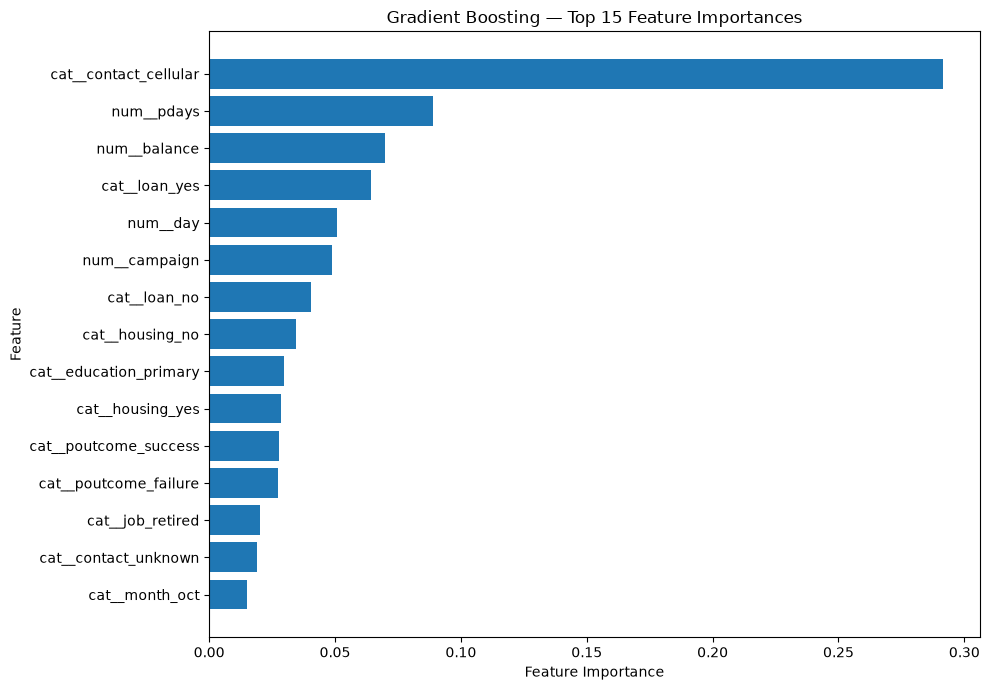


Feature importance saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/business_insights/01_feature_importance.png
Feature importance CSV saved.

Feature importance analysis completed successfully.


In [6]:

# ============================================================
# 5. FEATURE IMPORTANCE ANALYSIS — GRADIENT BOOSTING
# ============================================================

import ast
import json
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.ensemble import GradientBoostingClassifier
from src.preprocessing import (
    build_smotenc_model_pipeline,
    split_data
)

# 1. Extract selected model parameters
best_params_raw = selected_row.iloc[0]["Best Parameters"]

if isinstance(best_params_raw, str):
    best_params = ast.literal_eval(best_params_raw)
else:
    best_params = best_params_raw

# Remove pipeline prefixes if present
clean_params = {
    key.split("__")[-1]: value
    for key, value in best_params.items()
}

print("Selected Gradient Boosting parameters:")
print(json.dumps(clean_params, indent=4))

# 2. Prepare features and target
X = df.drop(columns=["y", "duration", "subscribed"], errors="ignore")
y = (df["y"] == "yes").astype(int)

X_train, X_val, y_train, y_val = split_data(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# 3. Build and train the selected model
gb_model = GradientBoostingClassifier(
    random_state=RANDOM_STATE,
    **clean_params
)

gb_pipeline = build_smotenc_model_pipeline(
    estimator=gb_model,
    random_state=RANDOM_STATE
)

gb_pipeline.fit(X_train, y_train)

print("\nSelected model trained successfully.")

# 4. Extract feature importance
preprocessor = gb_pipeline.named_steps["preprocessor"]
estimator = gb_pipeline.steps[-1][1]

feature_names = preprocessor.get_feature_names_out()
importance_values = estimator.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("\nTOP 15 IMPORTANT FEATURES")
print("=" * 60)

display(importance_df.head(15).round(5))

# 5. Save feature importance results
importance_df.to_csv(
    REPORT_DIR / "feature_importance.csv",
    index=False
)

# 6. Plot top 15 features
top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting — Top 15 Feature Importances")

plt.tight_layout()

figure_path = IMAGE_DIR / "01_feature_importance.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFeature importance saved:", figure_path)
print("Feature importance CSV saved.")

# 7. Validation
assert len(importance_df) == len(feature_names)
assert importance_df["Importance"].notna().all()
assert (importance_df["Importance"] >= 0).all()

print("\nFeature importance analysis completed successfully.")


PREDICTED PROBABILITY ANALYSIS


,Probability_Group,Total_Customers,Actual_Subscribers,Average_Predicted_Probability,Actual_Subscription_Rate
0,0-20%,372,17,0.104,4.570
1,20-40%,162,16,0.292,9.877
2,40-60%,210,29,0.495,13.810
3,60-80%,126,22,0.680,17.460
4,80-100%,35,20,0.862,57.143


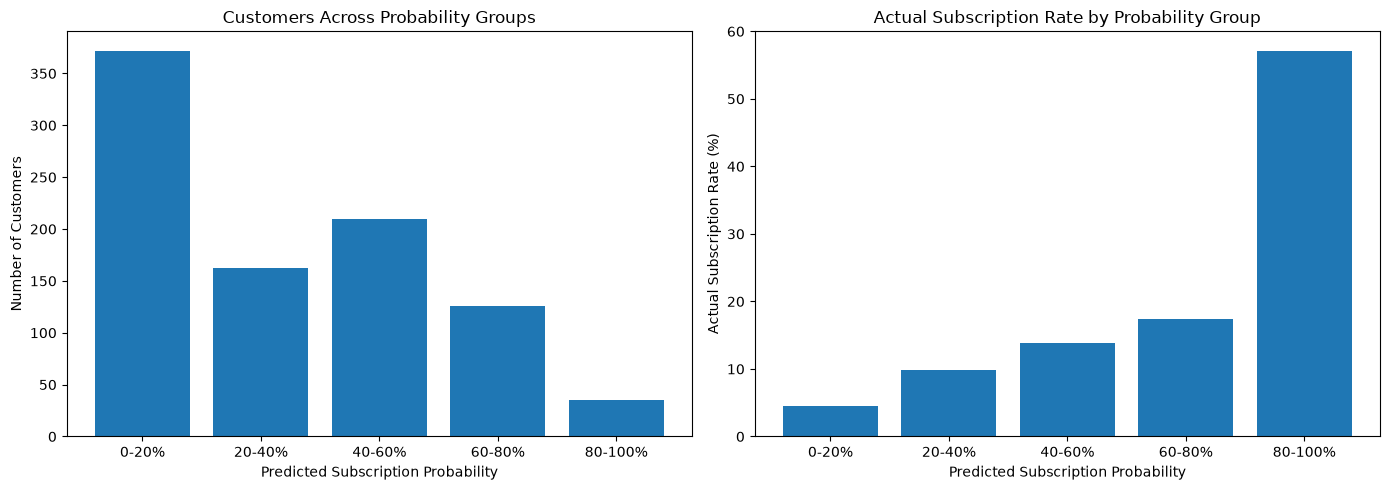


Probability analysis saved successfully.
CSV: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/reports/predicted_probability_analysis.csv
Figure: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/business_insights/02_predicted_probability_analysis.png


In [7]:

# ============================================================
# 6. PREDICTED PROBABILITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Predict subscription probabilities
y_probability = gb_pipeline.predict_proba(X_val)[:, 1]

probability_df = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted_Probability": y_probability
})

# 2. Create probability segments
probability_bins = [0, 0.2, 0.4, 0.6, 0.8, 1.000001]

probability_labels = [
    "0-20%",
    "20-40%",
    "40-60%",
    "60-80%",
    "80-100%"
]

probability_df["Probability_Group"] = pd.cut(
    probability_df["Predicted_Probability"],
    bins=probability_bins,
    labels=probability_labels,
    include_lowest=True
)

# 3. Analyze each probability group
probability_summary = (
    probability_df
    .groupby("Probability_Group", observed=False)
    .agg(
        Total_Customers=("Actual", "count"),
        Actual_Subscribers=("Actual", "sum"),
        Average_Predicted_Probability=(
            "Predicted_Probability", "mean"
        )
    )
    .reset_index()
)

probability_summary["Actual_Subscription_Rate"] = (
    probability_summary["Actual_Subscribers"]
    / probability_summary["Total_Customers"].replace(0, np.nan)
    * 100
)

print("PREDICTED PROBABILITY ANALYSIS")
print("=" * 65)

display(probability_summary.round(3))

# 4. Save probability analysis
probability_summary.to_csv(
    REPORT_DIR / "predicted_probability_analysis.csv",
    index=False
)

# 5. Visualize customer distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    probability_summary["Probability_Group"].astype(str),
    probability_summary["Total_Customers"]
)

axes[0].set_title("Customers Across Probability Groups")
axes[0].set_xlabel("Predicted Subscription Probability")
axes[0].set_ylabel("Number of Customers")

axes[1].bar(
    probability_summary["Probability_Group"].astype(str),
    probability_summary["Actual_Subscription_Rate"]
)

axes[1].set_title("Actual Subscription Rate by Probability Group")
axes[1].set_xlabel("Predicted Subscription Probability")
axes[1].set_ylabel("Actual Subscription Rate (%)")

plt.tight_layout()

figure_path = IMAGE_DIR / "02_predicted_probability_analysis.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Validation
assert len(probability_df) == len(X_val)
assert probability_df["Predicted_Probability"].between(0, 1).all()

print("\nProbability analysis saved successfully.")
print("CSV:", REPORT_DIR / "predicted_probability_analysis.csv")
print("Figure:", figure_path)


### Predicted Probability Analysis — Business Insights

**1. High-probability customers**

Customers in the 80–100% probability group achieved an actual subscription rate of 57.14%. The bank should prioritize these customers for personal calls and follow-ups.

**2. Low-probability customers**

The 0–20% group contains 372 customers, with an actual subscription rate of only 4.57%. The bank can reduce unnecessary calling efforts in this segment and consider lower-cost communication channels.

**3. Customer prioritization**

The bank should use predicted subscription probabilities to rank customers. Higher-probability customers can receive priority attention, while medium-probability customers can be approached through targeted campaigns.

**4. Business limitation**

Probability groups represent model predictions, not guaranteed customer decisions. The observed subscription rates are calculated on the validation dataset and may differ in future campaigns.

**5. Recommendation**

Use probability-based customer prioritization alongside campaign costs, customer preferences and available calling capacity. Monitor actual campaign outcomes before changing the marketing strategy.


## Marketing Recommendations, Limitations and Ethical Considerations

### 1. Marketing Recommendations

Based on the customer segmentation, feature importance and predicted probability analysis, the following recommendations are proposed:

- **Prioritize high-probability customers:** Focus calling efforts on customers with predicted subscription probabilities above 60%.
- **Use targeted campaigns:** Customers with medium probabilities (40–60%) can receive personalized offers and follow-up communication.
- **Reduce unnecessary calls:** Customers in the 0–20% group can be approached through lower-cost communication channels.
- **Consider previous campaign outcomes:** Customers with successful previous campaign outcomes showed a higher subscription rate. This information can help guide campaign prioritization.
- **Optimize campaign resources:** Allocate calling staff and campaign budgets according to predicted customer interest and available resources.
- **Monitor campaign performance:** Compare predicted probabilities with actual subscription outcomes and periodically evaluate model performance.

### 2. Model Limitations

- The dataset contains only 4,521 records, which may limit generalization to larger and different customer populations.
- The target variable is imbalanced, with approximately 11.52% positive subscription cases.
- The model identifies predictive relationships but cannot establish causal relationships.
- Customer behavior and campaign effectiveness may change over time.
- Predicted probabilities are not guaranteed subscription outcomes.
- The analysis uses a validation dataset; independent testing on future campaign data is required before production deployment.
- Feature importance can vary across models and should not be interpreted as proof of business causation.

### 3. Ethical Considerations

- **Customer privacy:** Customer information must be stored and processed securely.
- **Fairness:** Marketing decisions should avoid unfair discrimination against customer groups.
- **Transparency:** The bank should understand how model predictions influence customer prioritization.
- **Responsible communication:** Customers should not receive excessive or unwanted marketing calls.
- **Human oversight:** Final marketing decisions should involve human review rather than relying entirely on automated predictions.
- **Data protection:** Customer data should only be used for authorized business purposes and handled according to applicable data-protection requirements.

### 4. Final Business Conclusion

The Gradient Boosting model was selected based on its comparative validation performance, achieving a tuned F1-score of approximately 0.3128, PR-AUC of 0.3211 and ROC-AUC of 0.7171.

The analysis demonstrates that machine learning can help banks identify potential subscribers, understand important customer characteristics and prioritize marketing campaigns.

By combining predictive probabilities with customer segmentation, responsible communication and human oversight, the bank can make more informed marketing decisions.

**Final Recommendation:** Use the selected model as a decision-support tool for targeted marketing, subject to independent testing, fairness checks and continuous performance monitoring.

In [9]:

# ============================================================
# PHASE 8 — FINAL AUDIT
# ============================================================

import json
from pathlib import Path

# Locate project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

NOTEBOOK_PATH = PROJECT_ROOT / "notebooks" / "07_business_insights.ipynb"
REPORT_DIR = PROJECT_ROOT / "reports"
IMAGE_DIR = PROJECT_ROOT / "images" / "business_insights"

checks = {}

# 1. Required files
required_files = {
    "Business insights notebook": NOTEBOOK_PATH,
    "Model comparison CSV": REPORT_DIR / "model_comparison.csv",
    "Feature importance CSV": REPORT_DIR / "feature_importance.csv",
    "Predicted probability CSV": REPORT_DIR / "predicted_probability_analysis.csv",
    "Feature importance figure": IMAGE_DIR / "01_feature_importance.png",
    "Probability analysis figure": IMAGE_DIR / "02_predicted_probability_analysis.png",
}

for name, path in required_files.items():
    checks[name] = path.exists() and (
        path.stat().st_size > 0 if path.exists() else False
    )

# 2. Notebook structure and execution errors
notebook_valid = False
no_execution_errors = False
code_cells_executed = False

if NOTEBOOK_PATH.exists():
    try:
        with open(NOTEBOOK_PATH, "r", encoding="utf-8") as file:
            notebook = json.load(file)

        notebook_valid = (
            notebook.get("nbformat") == 4
            and isinstance(notebook.get("cells"), list)
        )

        code_cells = [
            cell for cell in notebook.get("cells", [])
            if cell.get("cell_type") == "code"
        ]

        no_execution_errors = all(
            output.get("output_type") != "error"
            for cell in code_cells
            for output in cell.get("outputs", [])
        )

        code_cells_executed = all(
            cell.get("execution_count") is not None
            for cell in code_cells
            if "".join(cell.get("source", [])).strip()
        )

    except (json.JSONDecodeError, OSError):
        pass

checks["Notebook JSON valid"] = notebook_valid
checks["No saved execution errors"] = no_execution_errors
checks["All non-empty code cells executed"] = code_cells_executed

# 3. Dataset analysis outputs
try:
    import pandas as pd

    feature_df = pd.read_csv(REPORT_DIR / "feature_importance.csv")
    probability_df = pd.read_csv(
        REPORT_DIR / "predicted_probability_analysis.csv"
    )
    comparison_df = pd.read_csv(REPORT_DIR / "model_comparison.csv")

    checks["Feature importance data valid"] = (
        not feature_df.empty
        and {"Feature", "Importance"}.issubset(feature_df.columns)
    )

    checks["Probability analysis data valid"] = (
        len(probability_df) == 5
        and "Total_Customers" in probability_df.columns
        and probability_df["Total_Customers"].sum() == 905
    )

    checks["Five models in comparison report"] = (
        comparison_df["Model"].nunique() == 5
    )

except Exception as error:
    print("Data validation error:", error)
    checks["Analysis CSV validation"] = False

# 4. Print final audit
print("=" * 65)
print("PHASE 8 — BUSINESS INSIGHTS FINAL AUDIT")
print("=" * 65)

for name, passed in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}")

passed_count = sum(checks.values())
total_count = len(checks)

print("\n" + "=" * 65)
print(f"AUDIT RESULT: {passed_count}/{total_count} CHECKS PASSED")

if all(checks.values()):
    print("PHASE 8 AUDIT PASSED")
else:
    print("PHASE 8 AUDIT NEEDS ATTENTION")

print("=" * 65)


PHASE 8 — BUSINESS INSIGHTS FINAL AUDIT
[PASS] Business insights notebook
[PASS] Model comparison CSV
[PASS] Feature importance CSV
[PASS] Predicted probability CSV
[PASS] Feature importance figure
[PASS] Probability analysis figure
[PASS] Notebook JSON valid
[PASS] No saved execution errors
[PASS] All non-empty code cells executed
[PASS] Feature importance data valid
[PASS] Probability analysis data valid
[PASS] Five models in comparison report

AUDIT RESULT: 12/12 CHECKS PASSED
PHASE 8 AUDIT PASSED
